# 02 — 3D HAMSTER 官方六例推理

目标：加载一次官方 Planner，依次运行 sample_0 到 sample_5，保存原始输出、UVD/相机 XYZ 路点、二维叠加图、输入/输出校验、模型加载时间、单例推理时间和 GPU 显存。

先完整通过 01_planner_setup.ipynb。本 Notebook 不训练模型，也不接入 LIBERO。

In [ ]:
from datetime import datetime
from pathlib import Path
import json
import os
import subprocess

from IPython.display import Image as DisplayImage, display

PROJECT_ROOT = Path(os.environ.get("PROJECT_ROOT", "/content/vla-3d-trajectory-guidance")).resolve()
CONFIG_PATH = PROJECT_ROOT / "configs" / "planner_colab.json"
assert CONFIG_PATH.is_file(), CONFIG_PATH
config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))

PLANNER_PY = Path(config["planner"]["env_dir"]) / "bin" / "python"
CHECKOUT_DIR = Path(config["planner"]["checkout_dir"])
EXAMPLES_DIR = CHECKOUT_DIR / config["planner"]["examples_subdir"]
CHECKPOINT_DIR = Path(config["planner"]["checkpoint_dir"])
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "planner" / RUN_ID
SAMPLES = [f"sample_{index}" for index in range(6)]

assert PLANNER_PY.is_file(), "Planner 环境不存在，请先运行 01 Notebook"
assert (CHECKPOINT_DIR / "model.safetensors.index.json").is_file(), "checkpoint 不完整"
assert all((EXAMPLES_DIR / f"{sample}_rgb.png").is_file() for sample in SAMPLES)
print("Output:", OUTPUT_DIR)


Output: /content/vla-3d-trajectory-guidance/outputs/planner/20261101_113926


## 1. 再次确认目标解释器和 CUDA

这一步通过后，推理脚本仍由同一个 /content/.venv_planner/bin/python 执行。

In [11]:
def planner_subprocess_env():
    env = os.environ.copy()
    npp_dir = Path(config["planner"]["env_dir"]) / "lib" / "python3.12" / "site-packages" / "nvidia" / "npp" / "lib"
    current = env.get("LD_LIBRARY_PATH", "")
    env["LD_LIBRARY_PATH"] = str(npp_dir) + (":" + current if current else "")
    return env

subprocess.run(
    [
        str(PLANNER_PY),
        str(PROJECT_ROOT / "scripts" / "check_planner_environment.py"),
        "--project-root",
        str(PROJECT_ROOT),
        "--config",
        str(CONFIG_PATH),
        "--gpu-test",
        "--output",
        str(OUTPUT_DIR / "environment_before_inference.json"),
    ],
    check=True,
    env=planner_subprocess_env(),
)


CompletedProcess(args=['/content/.venv_planner/bin/python', '/content/vla-3d-trajectory-guidance/scripts/check_planner_environment.py', '--project-root', '/content/vla-3d-trajectory-guidance', '--config', '/content/vla-3d-trajectory-guidance/configs/planner_colab.json', '--gpu-test', '--output', '/content/vla-3d-trajectory-guidance/outputs/planner/20261101_113926/environment_before_inference.json'], returncode=0)

## 2. 运行官方 sample_0 到 sample_5

脚本会继续尝试全部样例，并把每例错误写入对应目录；只要任一输出为空或非法，最终返回码就不是 0。

In [12]:
command = [
    str(PLANNER_PY),
    str(PROJECT_ROOT / "scripts" / "run_planner_inference.py"),
    "--project-root",
    str(PROJECT_ROOT),
    "--config",
    str(CONFIG_PATH),
    "--model-path",
    str(CHECKPOINT_DIR),
    "--examples-dir",
    str(EXAMPLES_DIR),
    "--output-dir",
    str(OUTPUT_DIR),
    "--samples",
    *SAMPLES,
    "--continue-on-error",
]
print("$", " ".join(command))
inference_process = subprocess.run(command, check=False, env=planner_subprocess_env())
print("Exit code:", inference_process.returncode)


$ /content/.venv_planner/bin/python /content/vla-3d-trajectory-guidance/scripts/run_planner_inference.py --project-root /content/vla-3d-trajectory-guidance --config /content/vla-3d-trajectory-guidance/configs/planner_colab.json --model-path /content/models/3D_HAMSTER --examples-dir /content/third_party/3D_HAMSTER/examples --output-dir /content/vla-3d-trajectory-guidance/outputs/planner/20261101_113926 --samples sample_0 sample_1 sample_2 sample_3 sample_4 sample_5 --continue-on-error
Exit code: 0


## 3. 汇总校验与可视化

{
  "all_valid": true,
  "completed_count": 6,
  "requested_count": 6,
  "model_load_seconds": 10.42431104800005,
  "samples": [
    {
      "name": "sample_0",
      "status": "ok",
      "inference_seconds": 7.079677509000021,
      "waypoint_count": 3,
      "errors": [],
      "runtime_error": null
    },
    {
      "name": "sample_1",
      "status": "ok",
      "inference_seconds": 7.299863949000041,
      "waypoint_count": 4,
      "errors": [],
      "runtime_error": null
    },
    {
      "name": "sample_2",
      "status": "ok",
      "inference_seconds": 5.556978805999961,
      "waypoint_count": 3,
      "errors": [],
      "runtime_error": null
    },
    {
      "name": "sample_3",
      "status": "ok",
      "inference_seconds": 7.203166244000045,
      "waypoint_count": 4,
      "errors": [],
      "runtime_error": null
    },
    {
      "name": "sample_4",
      "status": "ok",
      "inference_seconds": 7.345680154999968,
      "waypoint_count": 4,
      "errors": 

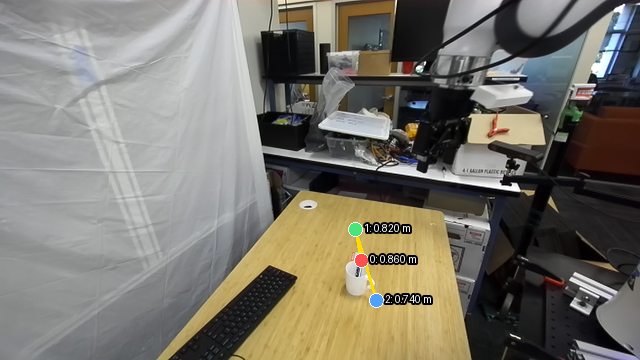

sample_1 pick up the red cup and place it on the table


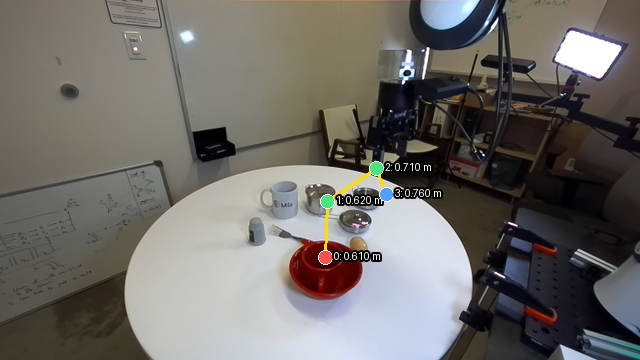

sample_2 Pick up the small book from the table and put it in the black basket.


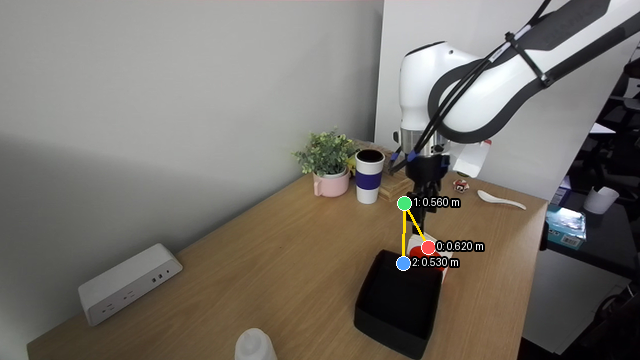

sample_3 Put the orange sharpie in the black cup


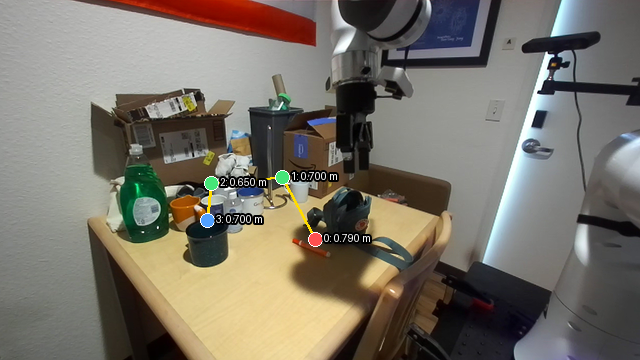

sample_4 Select the flower on ice and move it to the top drawer


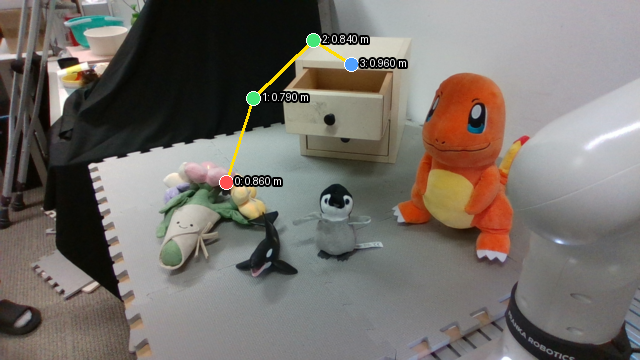

sample_5 What fruit is used to make wine? Place it in the white bowl.


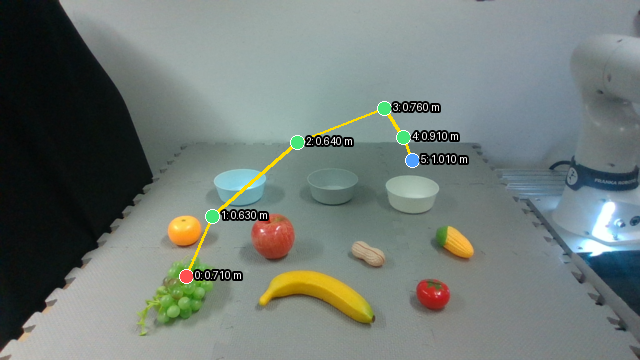

In [13]:
summary_path = OUTPUT_DIR / "run_summary.json"
assert summary_path.is_file(), summary_path
summary = json.loads(summary_path.read_text(encoding="utf-8"))

compact = {
    "all_valid": summary.get("all_valid"),
    "completed_count": summary.get("completed_count"),
    "requested_count": summary.get("requested_count"),
    "model_load_seconds": summary.get("model_load", {}).get("seconds"),
    "samples": [
        {
            "name": sample["name"],
            "status": sample["status"],
            "inference_seconds": sample.get("inference_seconds"),
            "waypoint_count": sample.get("output_validation", {}).get("metrics", {}).get("count"),
            "errors": sample.get("output_validation", {}).get("errors", []),
            "runtime_error": sample.get("error"),
        }
        for sample in summary["samples"]
    ],
}
print(json.dumps(compact, ensure_ascii=False, indent=2))

for sample in summary["samples"]:
    overlay = OUTPUT_DIR / sample["name"] / "trajectory_overlay.png"
    if overlay.is_file():
        print(sample["name"], sample["instruction"])
        display(DisplayImage(filename=str(overlay)))


## 4. 最终验收

下面断言只有在六例全部成功、非空、坐标有限且范围合法时通过。通过后再开始单帧 LIBERO 可行性验证。

In [14]:
assert inference_process.returncode == 0, "至少一个样例执行失败或输出非法，请查看 run_summary.json"
assert summary.get("requested_count") == 6
assert summary.get("completed_count") == 6
assert summary.get("all_valid") is True
print("3D HAMSTER 官方六例推理验收通过。")


3D HAMSTER 官方六例推理验收通过。
